In [47]:
import pandas as pd
import numpy as np

import datetime as datetime
import matplotlib as plot

In [2]:
luthera = pd.read_pickle('luthera_eph.pkl')

In [13]:
run_results = pd.read_pickle('results_20230402_1944.pkl')
run_results.set_index("int_length", inplace=True)

In [4]:
run_results.head()

,file,clock_time
int_length,,
1000000.0,0001,141.180673
2500000.0,0001,341.239845
5000000.0,0001,675.755479
7500000.0,0001,996.565786
10000000.0,0001,1335.806656


file
0000    AxesSubplot(0.125,0.11;0.775x0.77)
0001    AxesSubplot(0.125,0.11;0.775x0.77)
0002    AxesSubplot(0.125,0.11;0.775x0.77)
0003    AxesSubplot(0.125,0.11;0.775x0.77)
0004    AxesSubplot(0.125,0.11;0.775x0.77)
0005    AxesSubplot(0.125,0.11;0.775x0.77)
Name: clock_time, dtype: object

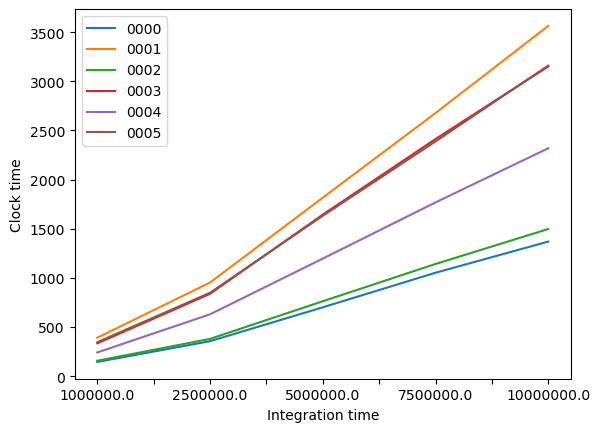

In [14]:
run_results.groupby("file")["clock_time"].plot(legend=True, xlabel="Integration time", ylabel="Clock time")


In [42]:
avg_int_time = run_results.groupby("int_length")["clock_time"].mean()

int_time = [float(int_time) for int_time in avg_int_time.index]

lin_fit = np.polyfit(int_time, avg_int_time,1)
reg_fun = np.poly1d(lin_fit)


In [49]:
print(reg_fun(int_time))
print(datetime.timedelta(seconds=reg_fun(2.25e9)))
print(datetime.timedelta(seconds=reg_fun(4.5e9)))

[ 285.67015104 2521.32439722  658.27919207 1279.29426045 1900.30932884]
6 days, 11:15:50.825668
12 days, 22:31:04.387211


In [15]:
luthera.head()

,ast_name,X,Y,Z,VX,VY,VZ,sX,sY,sZ,sVX,sVY,sVZ
0,1303,3.359408,-0.452480,-1.186056,0.000004,0.000023,0.000001,8.701710e-08,3.175031e-07,4.760651e-08,2.065703e-12,5.448479e-13,7.446493e-13
1,11911,2.140391,1.429843,-0.830626,-0.000017,0.000025,-0.000005,3.203728e-07,4.665975e-07,1.742568e-07,4.152455e-12,3.025382e-12,2.640732e-12
2,16794,0.840324,-3.311674,0.736326,0.000022,0.000008,-0.000007,4.350451e-07,1.687924e-07,2.637303e-07,1.247162e-12,3.006111e-12,1.577562e-12
3,17840,2.750743,-0.702947,0.541571,0.000010,0.000026,-0.000007,1.709369e-07,4.277067e-07,1.138321e-07,3.940652e-12,1.153119e-12,8.622816e-13
4,26558,-2.853475,1.822653,0.823708,-0.000015,-0.000018,-0.000005,4.011603e-07,3.906963e-07,2.627875e-07,3.288813e-12,2.191531e-12,2.217837e-12


<AxesSubplot: xlabel='X', ylabel='Y'>

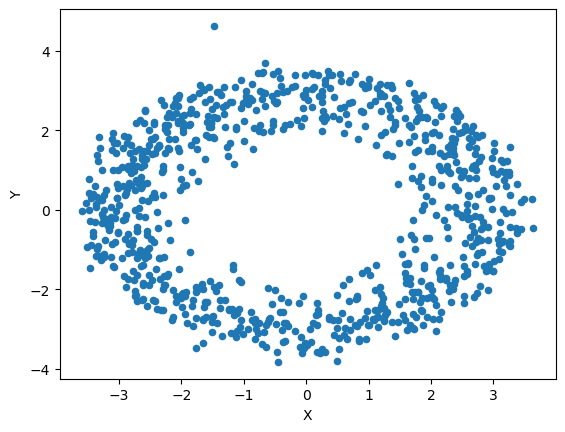

In [16]:
luthera[['X','Y','Z']].plot.scatter(x='X',y='Y')

<AxesSubplot: xlabel='X', ylabel='Z'>

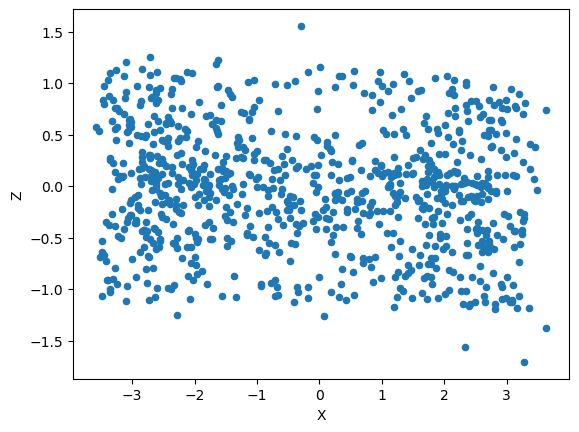

In [17]:
luthera[['X','Y','Z']].plot.scatter(x='X',y='Z')

<AxesSubplot: xlabel='Y', ylabel='Z'>

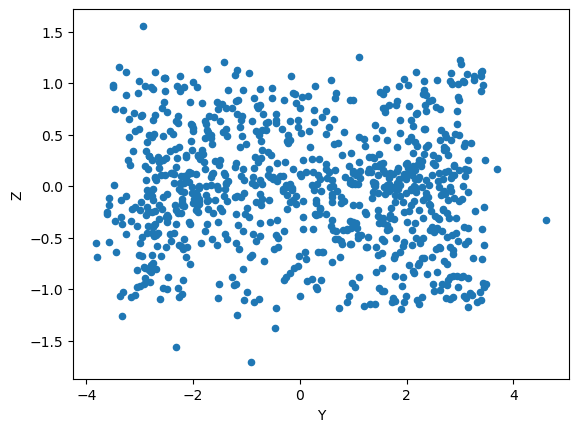

In [19]:
luthera[['X','Y','Z']].plot.scatter(x='Y',y='Z')

64